# Шаг 5. Боремся с переобучением: аугментация и dropout

В шаге 4 сеть начала **запоминать** обучающие фото вместо того, чтобы находить общие признаки.
Две простые и очень популярные защиты от этого:

**1. Аугментация данных** (*data augmentation*) — «размножение» картинок. Каждый раз, когда сеть берёт фото
для обучения, мы его **случайно немного меняем**: отражаем зеркально, сдвигаем, меняем яркость.
Кошка в зеркале — всё ещё кошка, но для сети это новые числа. В итоге сеть почти никогда не видит
одну и ту же картинку дважды и не может её просто запомнить.

**2. Dropout** («выбрасывание») — при обучении каждый нейрон классификатора с вероятностью `p` временно **выключается** (выдаёт 0).
Сети приходится не полагаться на один-два «любимых» нейрона, а распределять знание по многим.
При проверке (`model.eval()`) dropout выключается сам, и работают все нейроны.

**Структура примера (алгоритм):**
1. Описываем цепочку случайных преобразований `augment`.
2. Смотрим, как выглядит одна картинка после восьми разных аугментаций.
3. Создаём обучающий набор с аугментацией (проверочный — без неё!) и сеть с `dropout=0.3`.
4. Обучаем 40 эпох — аугментированные данные сложнее, учиться нужно дольше.
5. Сохраняем в `cnn_aug.pt` и сравниваем графики с сетью из шага 4.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session04")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

    # Набор данных скачивается на Диск один раз, потом берётся готовый
    from torchvision import datasets

    datasets.CIFAR10(f"{COLAB_ROOT}/data", download=True)

## Общий модуль `common.py`

Во всех примерах этой сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `CatsDogs(train, transform)` | набор данных: только кошки и собаки из CIFAR-10. Обучающий (`train=True`) — 10 000 картинок, проверочный — 2 000. Метки: 0 — кошка, 1 — собака |
| `CLASSES`, `CLASSES_RU` | названия классов: `["cat", "dog"]` и `["кошка", "собака"]` |
| `MLP` | полносвязная сеть из сессии 3, только вход 3 × 32 × 32 = 3072 числа |
| `SimpleCNN(dropout)` | простая свёрточная сеть: три блока «свёртка → ReLU → пулинг» и классификатор |
| `train(model, train_set, test_set, epochs)` | цикл обучения из сессии 3; после каждой эпохи пишет точность на обучающих и проверочных картинках |
| `accuracy`, `predict_all` | точность сети на наборе и вероятности классов для всех картинок |
| `save_model`, `load_model`, `load_history` | сохранить / загрузить веса (`*.pt`) и историю обучения (`*.json`) |
| `count_params(model)` | сколько весов в сети |
| `show()` | показать графики matplotlib |

> Запускайте примеры из папки `session04`, иначе `import common` не найдёт модуль.
> Библиотеки: `pip install -r requirements.txt`. CIFAR-10 берётся из локальной папки `data/cifar-10-batches-py`, интернет не нужен.

## 1. Цепочка аугментаций

Используем модуль `torchvision.transforms.v2` (`T`). `T.Compose` склеивает преобразования в цепочку, они применяются по очереди:

| Преобразование | Что делает |
|----------------|------------|
| `RandomHorizontalFlip()` | с вероятностью 50% отражает картинку слева направо |
| `RandomCrop(32, padding=4, padding_mode="reflect")` | дописывает по 4 пикселя с каждой стороны (зеркальным отражением края) и вырезает случайный квадрат 32 × 32 — то есть сдвигает картинку на 0–4 пикселя в любую сторону |
| `ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2)` | случайно меняет яркость, контраст и насыщенность до ±20% |

> Вертикальное отражение мы **не** используем: кошка вверх ногами в жизни почти не встречается.
> Аугментация должна создавать картинки, которые **могли бы** быть в реальных данных.

In [1]:
import matplotlib.pyplot as plt
import torch
import torchvision.transforms.v2 as T

from common import CLASSES, CatsDogs, SimpleCNN, load_history, save_model, show, train

augment = T.Compose([
    T.RandomHorizontalFlip(),                                      # зеркало
    T.RandomCrop(32, padding=4, padding_mode="reflect"),           # сдвиг до 4 пикселей
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),   # освещение
])

## 2. Как выглядит аугментация

Берём одну картинку из исходного набора и 8 раз применяем к ней `augment` — каждый раз получается немного другая.
`.clamp(0, 1)` обрезает числа до допустимого диапазона, если изменение яркости вывело их за пределы.

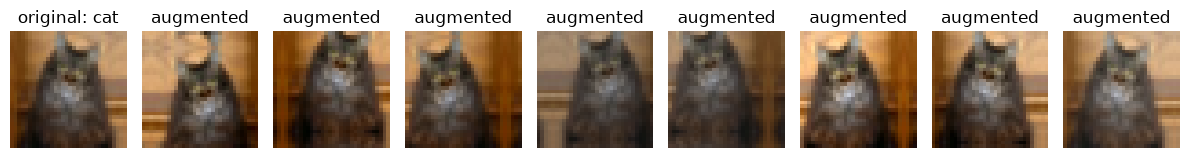

In [2]:
torch.manual_seed(0)
plain = CatsDogs(train=True)
image, label = plain[3]

fig, axes = plt.subplots(1, 9, figsize=(12, 1.9))
axes[0].imshow(image.permute(1, 2, 0))
axes[0].set_title(f"original: {CLASSES[label]}")
for ax in axes[1:]:
    ax.imshow(augment(image).clamp(0, 1).permute(1, 2, 0))
    ax.set_title("augmented")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("augment.png", dpi=100)
show()

## 3. Обучение с аугментацией и dropout

- `CatsDogs(train=True, transform=augment)` — обучающий набор, который при **каждой** выдаче картинки применяет `augment`.
  Изменения не сохраняются: в следующей эпохе та же картинка изменится по-другому.
- Проверочный набор — **без аугментации**: проверяем на настоящих картинках.
- `SimpleCNN(dropout=0.3)` — та же архитектура, но в классификаторе 30% нейронов на каждом шаге случайно выключаются.

Задача стала труднее, поэтому учим дольше — 40 эпох (на обычном ноутбуке около 2–4 минут).
Точность на обучающих картинках теперь будет **ниже**, чем в шаге 4, — это нормально и даже хорошо: сеть больше не зубрит.

In [ ]:
torch.manual_seed(0)
train_set = CatsDogs(train=True, transform=augment)
test_set = CatsDogs(train=False)

model = SimpleCNN(dropout=0.3)
history = train(model, train_set, test_set, epochs=40)
save_model(model, "cnn_aug", history)

Эпоха  1: на обучающих 53.9%, на проверочных 61.8%
Эпоха  2: на обучающих 61.4%, на проверочных 64.3%
Эпоха  3: на обучающих 63.7%, на проверочных 67.4%
Эпоха  4: на обучающих 66.0%, на проверочных 68.3%
Эпоха  5: на обучающих 68.3%, на проверочных 72.9%
Эпоха  6: на обучающих 70.0%, на проверочных 73.2%
Эпоха  7: на обучающих 71.8%, на проверочных 73.6%
Эпоха  8: на обучающих 72.7%, на проверочных 74.7%
Эпоха  9: на обучающих 72.9%, на проверочных 76.7%
Эпоха 10: на обучающих 74.1%, на проверочных 76.6%
Эпоха 11: на обучающих 74.3%, на проверочных 76.7%
Эпоха 12: на обучающих 74.6%, на проверочных 77.5%
Эпоха 13: на обучающих 75.8%, на проверочных 78.6%
Эпоха 14: на обучающих 75.9%, на проверочных 78.1%
Эпоха 15: на обучающих 76.7%, на проверочных 76.0%
Эпоха 16: на обучающих 76.8%, на проверочных 79.1%
Эпоха 17: на обучающих 77.0%, на проверочных 79.9%
Эпоха 18: на обучающих 77.5%, на проверочных 79.0%
Эпоха 19: на обучающих 78.0%, на проверочных 77.3%
Эпоха 20: на обучающих 77.9%, н

## 4. Сравнение с шагом 4

Сплошные линии — сеть из шага 4 (из `cnn.json`), пунктир — новая сеть.
Что обычно видно:
- **разрыв** между обучающей и проверочной точностью стал намного меньше — переобучение побеждено;
- точность на **проверочных** выше, чем в шаге 4, и продолжает расти даже на поздних эпохах.

In [ ]:
plt.figure(figsize=(7, 3.8))
plain_cnn = load_history("cnn")
if plain_cnn:
    e = range(1, len(plain_cnn["train"]) + 1)
    plt.plot(e, plain_cnn["train"], "o-", color="C0", label="шаг 4: обучающие")
    plt.plot(e, plain_cnn["test"], "o-", color="C1", label="шаг 4: проверочные")
e = range(1, len(history["train"]) + 1)
plt.plot(e, history["train"], "s--", color="C0", label="аугментация: обучающие")
plt.plot(e, history["test"], "s--", color="C1", label="аугментация: проверочные")
plt.xlabel("эпоха")
plt.ylabel("точность")
plt.title("Аугментация и dropout против переобучения")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("aug_curves.png", dpi=100)
show()

## Попробуйте сами

1. Обучите сеть только с аугментацией (`dropout=0`) и только с dropout (без `transform`). Что даёт больший эффект?
2. Добавьте `T.RandomRotation(15)` — поворот до ±15°. Становится ли лучше?
3. Добавьте `T.RandomVerticalFlip()`. Почему точность, скорее всего, упадёт?
4. Поставьте `dropout=0.7`. Что происходит с обучением?